# TP2 - Reconstrucción 3D
**I308 Visión Artificial - Universidad de San Andrés**

Este notebook recorre el pipeline paso a paso, mostrando el resultado de cada etapa.
No duplica código: llama a las funciones de `pipeline/` (las mismas que usa
`python pipeline/run_pipeline.py configs/<dataset>.yaml`).

1. Calibración y rectificación estéreo
2. Disparidad y nube local (un par en detalle)
3. Pose con el objeto de referencia (ChArUco) y transformación al mundo
4. Reconstrucción de todas las capturas
5. Fusión y optimización en Open3D
6. Malla con Poisson (opcional)
7. Medición métrica

## 0. Setup

Funciona local (con el `.venv` del README) o en **Google Colab**: en Colab clona el
repo e instala las dependencias.

In [1]:
import os
import sys

REPO_URL = "https://github.com/pepoberess/tp2-reconstruccion-3d"
BRANCH = "cami"

try:
    import google.colab  # noqa: F401
    COLAB = True
except ImportError:
    COLAB = False

if COLAB:
    if not os.path.exists("tp2-reconstruccion-3d"):
        !git clone -q --branch {BRANCH} {REPO_URL}
    %cd tp2-reconstruccion-3d
    # sin fijar numpy: Colab ya trae uno compatible
    !pip install -q opencv-python==4.13.0.92 opencv-contrib-python==4.13.0.92 open3d==0.19.0 onnxruntime pyyaml

REPO_ROOT = os.path.abspath(".")
sys.path.insert(0, os.path.join(REPO_ROOT, "pipeline"))
print("COLAB:", COLAB, "| repo:", REPO_ROOT)

COLAB: False | repo: /Users/camidipaola/Desktop/VISION ARTIFICIAL/tp2-grupo


In [2]:
import cv2
import matplotlib.pyplot as plt
import numpy as np
import open3d as o3d
import yaml
from IPython.display import Image, display

import calibration as stereo_calib
import fusion
import pose as pose_mod
import run_pipeline as rp
import stereo
from dataset import list_stereo_pairs, read_markers_yaml

print("OpenCV", cv2.__version__, "| Open3D", o3d.__version__, "| NumPy", np.__version__)


def show(path, width=1000):
    display(Image(filename=path, width=width))


def show_cloud(points, colors, title, max_points=40000, elev=25, azim=-60):
    """Nube de puntos con matplotlib (submuestreada)."""
    if len(points) > max_points:
        sel = np.random.default_rng(0).choice(len(points), max_points, replace=False)
        points, colors = points[sel], colors[sel]
    fig = plt.figure(figsize=(8, 6))
    ax = fig.add_subplot(projection="3d")
    ax.scatter(points[:, 0], points[:, 1], points[:, 2], c=colors, s=0.3)
    ax.set_box_aspect(np.ptp(points, axis=0))
    ax.view_init(elev=elev, azim=azim)
    ax.set_xlabel("X [mm]"); ax.set_ylabel("Y [mm]"); ax.set_zlabel("Z [mm]")
    ax.set_title(title)
    plt.show()

OpenCV 4.13.0 | Open3D 0.19.0 | NumPy 2.4.6


### Configuración

Cada dataset tiene un `.yaml` en `configs/` (caja del objeto, parámetros de disparidad,
filtros, etc.). `configs/grupo.yaml` es nuestro dataset (peluche sobre un ChArUco 9x13).

**Disparidad**: la config del grupo usa **CREStereo** (red neuronal, ~15 s por par en CPU,
~15 min para las 58 capturas). En Colab, por defecto usamos **SGBM** (segundos) salvo que
se ponga `USE_CRESTEREO = True`.

In [3]:
CONFIG = "configs/grupo.yaml"
USE_CRESTEREO = None   # None: lo que diga la config (en Colab: SGBM). True / False para forzar.

with open(CONFIG) as f:
    cfg = yaml.safe_load(f)

if USE_CRESTEREO is None:
    USE_CRESTEREO = (cfg.get("disparity_method") == "crestereo") and not COLAB
cfg["disparity_method"] = "crestereo" if USE_CRESTEREO else "sgbm"
if not USE_CRESTEREO and cfg["output"] == "output/grupo":
    cfg["output"] = "output/grupo_sgbm"   # no pisar los resultados de CREStereo

if USE_CRESTEREO:
    model = os.path.join(cfg["crestereo"]["models_dir"], "crestereo_combined_iter10_720x1280.onnx")
    if not os.path.exists(model):
        os.makedirs(os.path.dirname(model), exist_ok=True)
        !curl -sL -o {model} https://github.com/nburrus/stereodemo/releases/download/v0.1-crestereo/crestereo_combined_iter10_720x1280.onnx

dataset_dir = rp.resolve(cfg["dataset"])
out_dir = rp.resolve(cfg["output"])
fig_dir = os.path.join(out_dir, "figures")
inter_dir = os.path.join(out_dir, "intermediate")
for d in (out_dir, fig_dir, inter_dir):
    os.makedirs(d, exist_ok=True)

print("dataset:", dataset_dir)
print("salidas:", out_dir)
print("disparidad:", rp.method_name(cfg))

dataset: /Users/camidipaola/Desktop/VISION ARTIFICIAL/tp2-grupo/tp2_reconstruccion_3d/datasets
salidas: /Users/camidipaola/Desktop/VISION ARTIFICIAL/tp2-grupo/output/grupo
disparidad: CREStereo


## 1. Calibración y rectificación estéreo

- Se detecta el checkerboard en cada par de `calib/` (`findChessboardCorners` + `cornerSubPix`).
- `stereoCalibrateExtended` estima los intrínsecos de cada cámara (K, distorsión) y la
  rotación/traslación entre ellas (R, T). También da el error de reproyección por par.
- `stereoRectify` + `initUndistortRectifyMap` generan los mapas que, aplicados con `remap`,
  dejan las líneas epipolares horizontales.

In [4]:
calibration, maps = rp.step_calibration(cfg, dataset_dir, out_dir, fig_dir)


[4.1] Calibración y rectificación estéreo
  checkerboard (9, 6), cuadrado 28.0 mm


  checkerboard detectado en 81 pares


  RMS estéreo: 1.074px


  left_K = np.array([
	[   604.513,	     0.000,	   951.726],
	[     0.000,	   602.136,	   539.916],
	[     0.000,	     0.000,	     1.000]
])
  left_dist = np.array([
	[  0.016693,	 -0.031279,	 -0.000017,	  0.000204,	  0.005448]
])
  right_K = np.array([
	[   605.676,	     0.000,	   949.507],
	[     0.000,	   603.009,	   527.222],
	[     0.000,	     0.000,	     1.000]
])
  right_dist = np.array([
	[  0.019067,	 -0.032733,	 -0.000245,	  0.000258,	  0.005754]
])
  R = np.array([
	[     1.000,	    -0.001,	     0.017],
	[     0.001,	     1.000,	    -0.002],
	[    -0.017,	     0.002,	     1.000]
])
  T = np.array([
	[-60.701646],
	[  0.279461],
	[ -0.391900]
])
  baseline = 60.70 mm


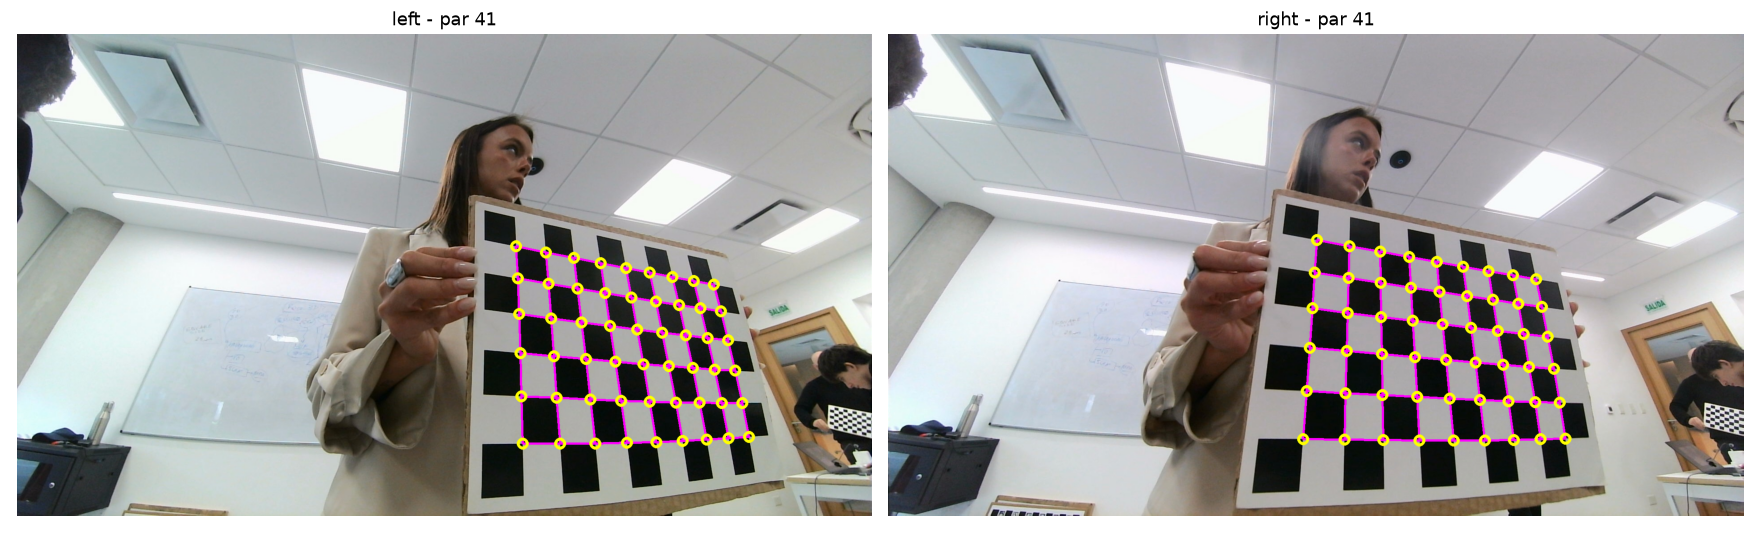

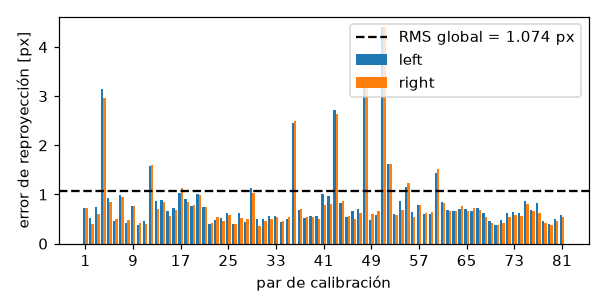

In [5]:
show(os.path.join(fig_dir, "00_deteccion_checkerboard.png"))
show(os.path.join(fig_dir, "00_error_por_vista.png"))

Original vs. rectificada: después de rectificar, un mismo punto de la escena queda en la
**misma fila** en ambas imágenes (líneas verdes).

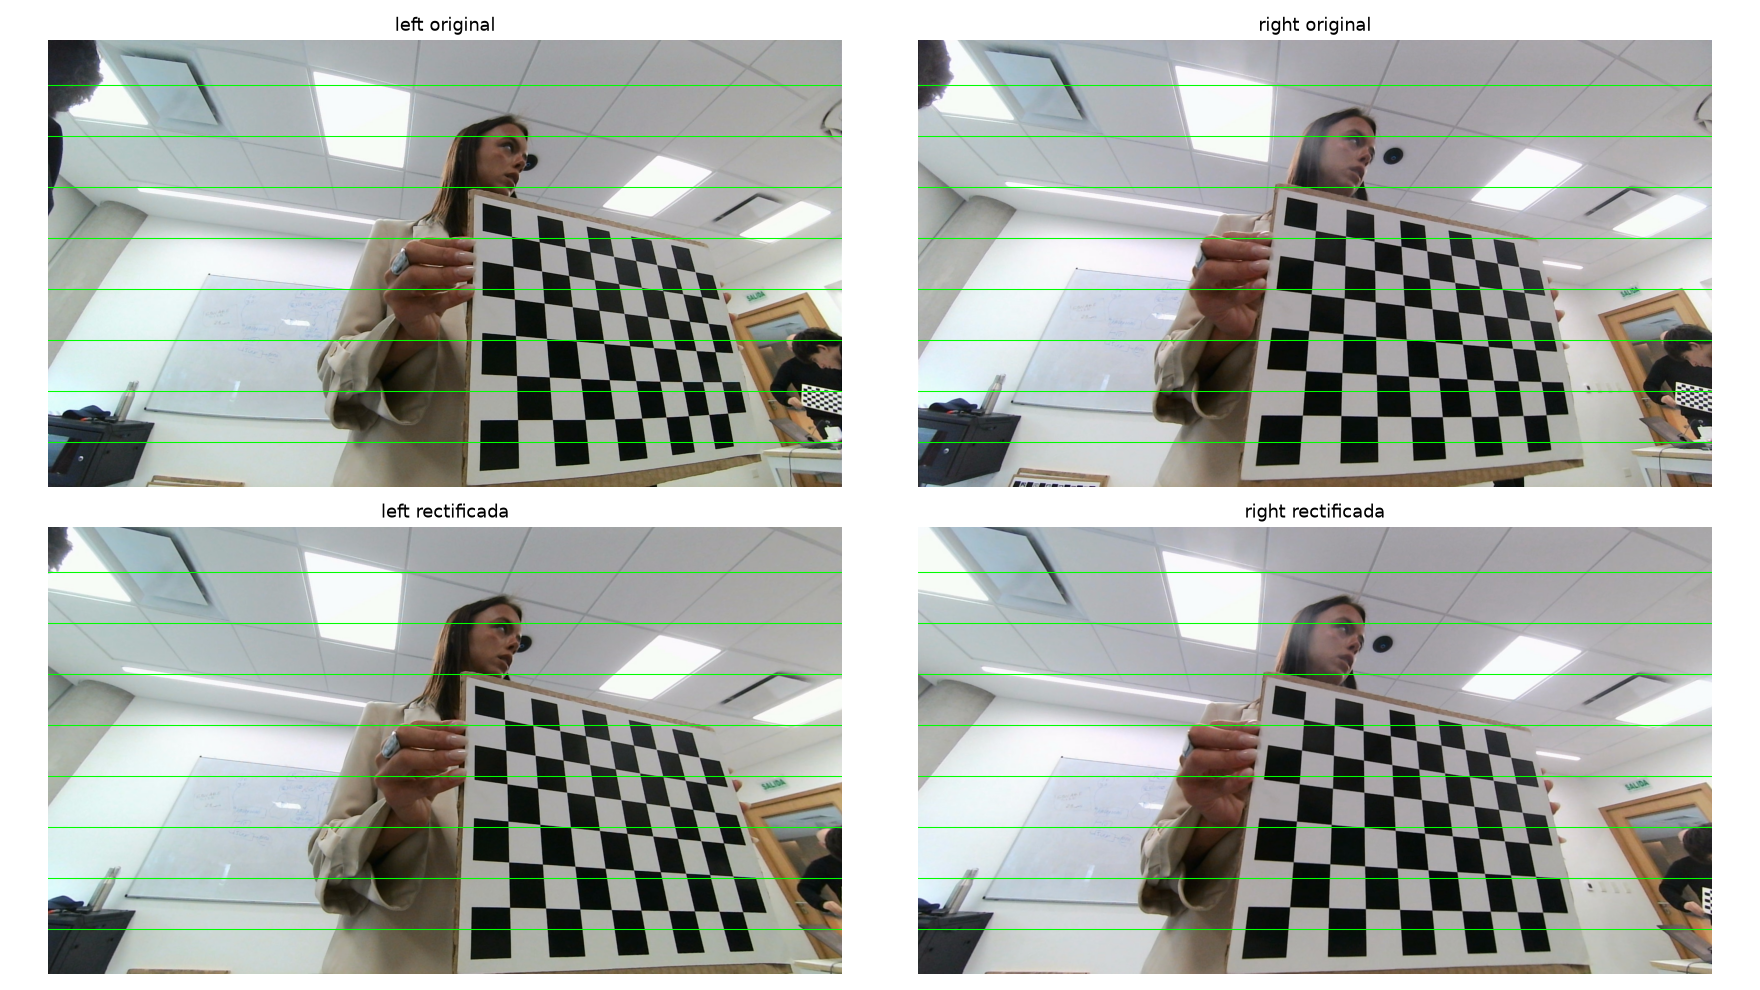

In [6]:
show(os.path.join(fig_dir, "01_rectificacion_calib.png"))

## 2. Disparidad y nube local (un par en detalle)

Sobre el par rectificado se busca, para cada píxel de la izquierda, su correspondiente en la
misma fila de la derecha. La diferencia en x es la disparidad `d`, y la profundidad es
`Z = f·B / d`. `reprojectImageTo3D` hace esa cuenta con la matriz `Q` de `stereoRectify`
y devuelve (X, Y, Z) en mm en el sistema de la cámara izquierda rectificada.

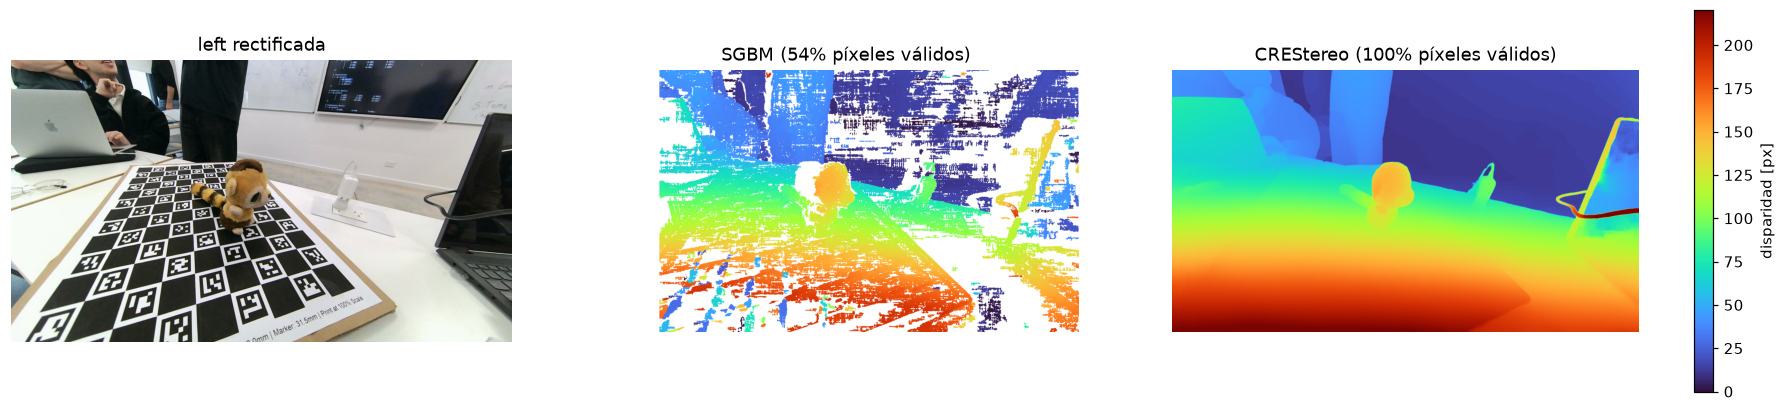

In [7]:
captures_dir = os.path.join(dataset_dir, "captures")
pairs = list_stereo_pairs(captures_dir)
idx, lf, rf = pairs[0]

left, right = cv2.imread(lf), cv2.imread(rf)
left_r, right_r = stereo_calib.rectify_pair(left, right, maps)

disparity = rp.compute_disparity(cfg, left_r, right_r, idx, inter_dir)
sgbm = stereo.compute_disparity(cv2.cvtColor(left_r, cv2.COLOR_BGR2GRAY),
                                cv2.cvtColor(right_r, cv2.COLOR_BGR2GRAY), cfg.get("sgbm"))

if USE_CRESTEREO:
    rp.save_disparity_comparison(left_r, sgbm, disparity, os.path.join(fig_dir, "03b_sgbm_vs_crestereo.png"))
    show(os.path.join(fig_dir, "03b_sgbm_vs_crestereo.png"), width=1100)
else:
    rp.save_disparity_figure(left_r, disparity, os.path.join(fig_dir, "03_disparidad.png"), "disparidad SGBM [px]")
    show(os.path.join(fig_dir, "03_disparidad.png"))

nube local del par 0: 1,467,128 puntos


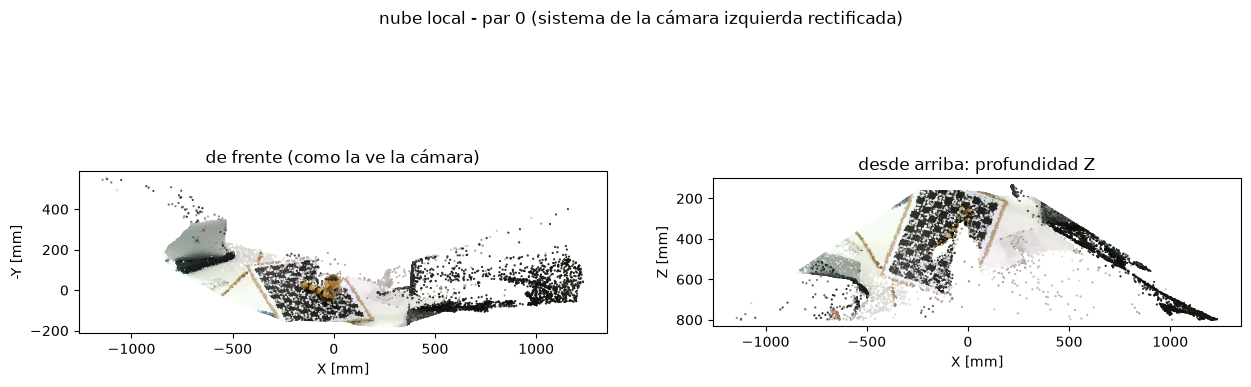

In [8]:
Q = maps["Q"]
local_points, local_colors = stereo.disparity_to_points(disparity, Q, left_r, z_range=cfg["z_range"])
print(f"nube local del par {idx}: {len(local_points):,} puntos")

# dos vistas 2D de la nube local, solo la zona cercana (Z < 800 mm)
near = local_points[:, 2] < 800
pts, cols = local_points[near], local_colors[near]
sel = np.random.default_rng(0).choice(len(pts), min(60000, len(pts)), replace=False)
fig, axes = plt.subplots(1, 2, figsize=(15, 5))
axes[0].scatter(pts[sel, 0], -pts[sel, 1], c=cols[sel], s=0.3)
axes[0].set_title("de frente (como la ve la cámara)"); axes[0].set_xlabel("X [mm]"); axes[0].set_ylabel("-Y [mm]")
axes[1].scatter(pts[sel, 0], pts[sel, 2], c=cols[sel], s=0.3)
axes[1].set_title("desde arriba: profundidad Z"); axes[1].set_xlabel("X [mm]"); axes[1].set_ylabel("Z [mm]")
axes[1].invert_yaxis()
for ax in axes:
    ax.set_aspect("equal")
fig.suptitle(f"nube local - par {idx} (sistema de la cámara izquierda rectificada)")
plt.show()

## 3. Pose con el ChArUco y transformación al mundo

- Se detectan los marcadores ArUco y se interpolan los corners ChArUco; cada uno tiene una
  posición 3D conocida en el tablero (en mm).
- `solvePnP` (IPPE, porque el patrón es plano) da `rvec, tvec`: la transformación
  **mundo → cámara**, `X_cam = R·X_world + t`. `rvec` es el **vector de Rodrigues**: su
  dirección es el eje de rotación y su norma el ángulo; `cv2.Rodrigues` lo pasa a la matriz R.
- Para llevar la nube local al mundo usamos la inversa: `X_world = Rᵀ·(X_cam − t)`.
- La pose se estima en la imagen izquierda **rectificada** con `K = P1[:, :3]` y sin
  distorsión, que es justamente el sistema donde `reprojectImageTo3D` da los puntos.

rvec (Rodrigues): [-1.014 -0.209 -0.266] -> ángulo 61.2°
R =
 [[ 0.948  0.314 -0.049]
 [-0.122  0.501  0.857]
 [ 0.294 -0.806  0.513]]
t (mm) = [-383.7 -103.8  552.4]
error de reproyección PnP: 2.15 px con 177 puntos


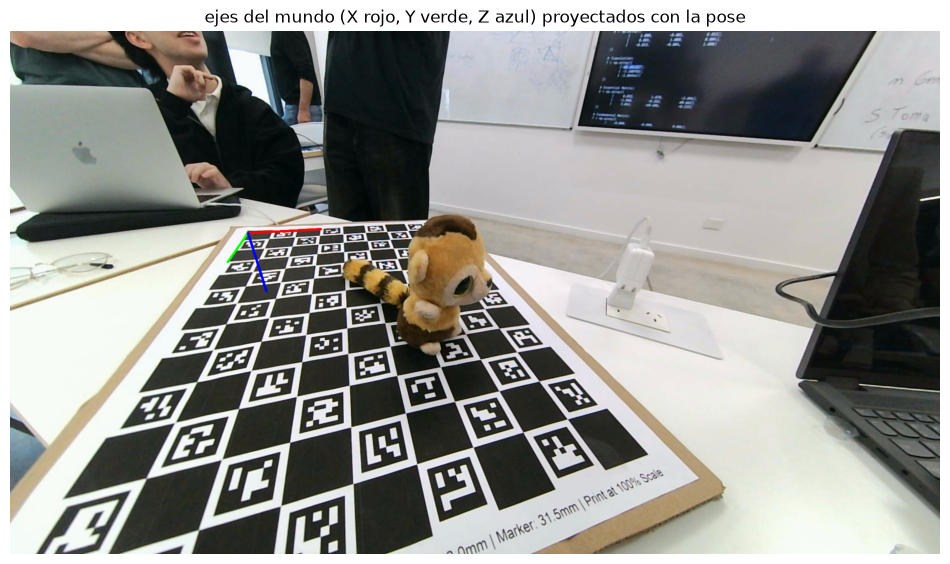

In [9]:
markers = read_markers_yaml(os.path.join(captures_dir, "markers.yaml"))
board = pose_mod.make_charuco_board(markers) if markers["type"] == "charuco" else None
K_rect = maps["P1"][:, :3]

p = pose_mod.estimate_pose(left_r, markers, K_rect, board=board)
R, _ = cv2.Rodrigues(p["rvec"])
print("rvec (Rodrigues):", p["rvec"].ravel().round(3), f"-> ángulo {np.degrees(np.linalg.norm(p['rvec'])):.1f}°")
print("R =\n", R.round(3))
print("t (mm) =", p["tvec"].ravel().round(1))
print(f"error de reproyección PnP: {p['reproj_error']:.2f} px con {p['num_points']} puntos")

axis_len = (markers.get("square_length") or markers.get("square_size")) * 3
vis = pose_mod.draw_pose(left_r, p["rvec"], p["tvec"], K_rect, axis_len=axis_len)
plt.figure(figsize=(12, 7)); plt.imshow(cv2.cvtColor(vis, cv2.COLOR_BGR2RGB)); plt.axis("off")
plt.title("ejes del mundo (X rojo, Y verde, Z azul) proyectados con la pose"); plt.show()

cámara en el mundo (mm): [ 188.9 -618.1  213.2]


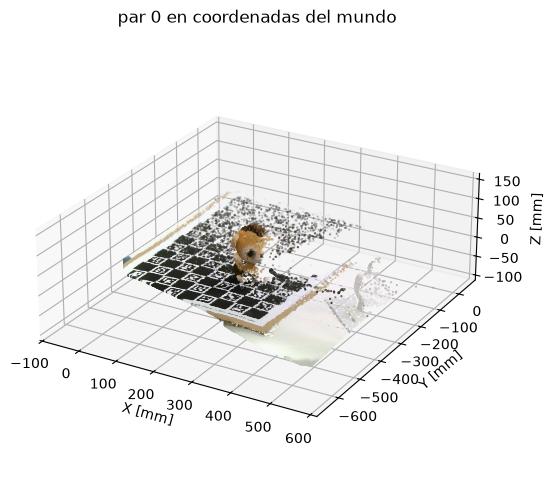

In [10]:
# local -> mundo (+ rotación de 180° sobre X para que Z apunte hacia arriba desde el tablero)
T_world_cam = rp.FLIP_Z_UP @ pose_mod.pose_to_matrix(p["rvec"], p["tvec"])
world_points = pose_mod.transform_points(local_points, T_world_cam)
print("cámara en el mundo (mm):", T_world_cam[:3, 3].round(1))

near = np.all((world_points > np.array(cfg["box_min"]) - 200) & (world_points < np.array(cfg["box_max"]) + 200), axis=1)
show_cloud(world_points[near], local_colors[near], f"par {idx} en coordenadas del mundo")

## 4. Reconstrucción de todas las capturas

Lo mismo para cada par: disparidad → nube local → pose → mundo. Con CREStereo la primera vez
tarda ~15 min (las disparidades quedan cacheadas en `intermediate/`).

In [11]:
pcd, poses_world, per_view, K_rect = rp.step_reconstruction(cfg, dataset_dir, maps, fig_dir, inter_dir)
print(f"\nnube fusionada: {len(pcd.points):,} puntos de {len(poses_world)} capturas")


[4.2] Disparidad, nube local y pose de cada captura
  objeto de referencia: {'type': 'charuco', 'dictionary': 'DICT_5X5_100', 'squares_x': 9, 'squares_y': 13, 'square_length': 42.0, 'marker_length': 31.5}
  captura  0: 1,467,128 pts | pose pnp (177 pts, err 2.15px) | cámara en [ 189. -618.  213.]


  captura  1:  930,316 pts | pose pnp (72 pts, err 2.54px) | cámara en [ 188. -606.  197.]
  captura  2: 1,458,520 pts | pose pnp (206 pts, err 3.11px) | cámara en [  75. -488.  249.]


  captura  3: 1,689,668 pts | pose pnp (246 pts, err 2.89px) | cámara en [  20. -406.  238.]
  captura  4: 1,521,405 pts | pose pnp (270 pts, err 2.11px) | cámara en [  12. -295.  293.]


  captura  5: 1,500,718 pts | pose pnp (258 pts, err 2.02px) | cámara en [  30. -224.  300.]
  captura  6: 1,502,572 pts | pose pnp (242 pts, err 2.00px) | cámara en [  45. -168.  291.]


  captura  7: 1,592,901 pts | pose pnp (258 pts, err 2.10px) | cámara en [  71. -105.  287.]
  captura  8: 1,251,969 pts | pose pnp (230 pts, err 2.31px) | cámara en [115. -99. 325.]


...

  captura 50: 2,073,600 pts | pose pnp (248 pts, err 2.37px) | cámara en [  49. -110.  266.]
  captura 51: 1,505,792 pts | pose pnp (165 pts, err 4.21px) | cámara en [ -29. -388.  112.]


  captura 52: 1,512,466 pts | pose pnp (269 pts, err 2.31px) | cámara en [ -78. -459.  302.]
  captura 53: 1,620,236 pts | pose pnp (269 pts, err 2.11px) | cámara en [-100. -475.  315.]


  captura 54: 1,820,389 pts | pose pnp (178 pts, err 2.51px) | cámara en [  82. -630.  184.]
  captura 55: 1,807,964 pts | pose pnp (145 pts, err 2.48px) | cámara en [  60. -634.  151.]


  captura 56: 1,681,656 pts | pose pnp (174 pts, err 2.37px) | cámara en [  78. -623.  193.]
  captura 57: 1,751,763 pts | pose pnp (157 pts, err 2.40px) | cámara en [ 158. -664.  181.]



nube fusionada: 100,043,139 puntos de 58 capturas


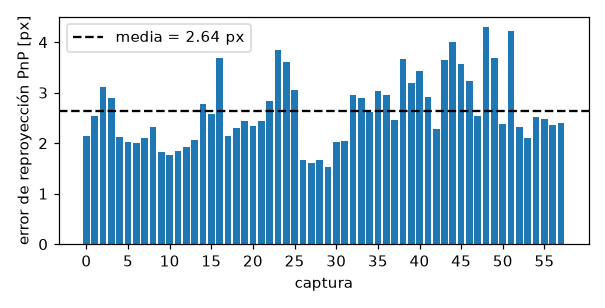

In [12]:
rp.save_pnp_errors_figure(per_view, os.path.join(fig_dir, "04b_error_pnp_por_captura.png"))
show(os.path.join(fig_dir, "04b_error_pnp_por_captura.png"))

Poses de cámara estimadas (pirámides rojas) sobre la escena: deberían seguir el recorrido
que hicimos alrededor del objeto al sacar las fotos.

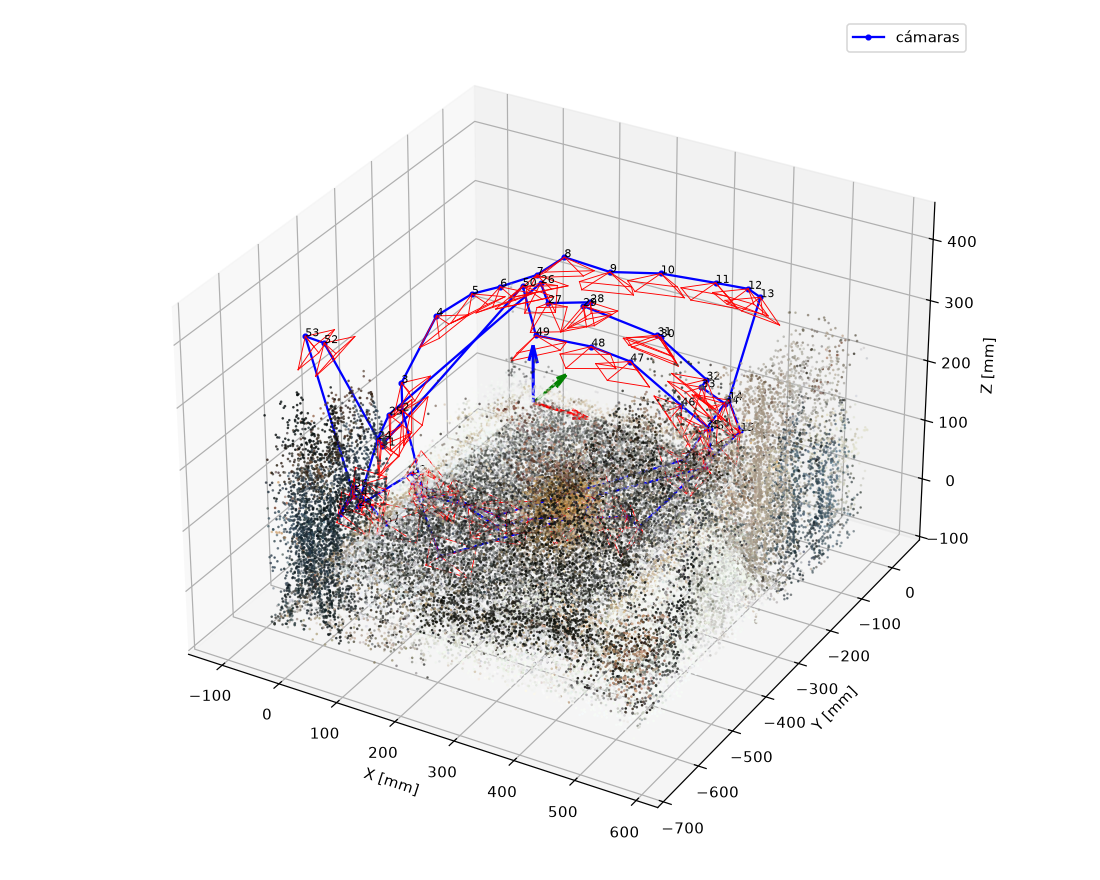

In [13]:
scene = pcd.voxel_down_sample(3.0)
margin = np.array([200, 200, 50])
scene_crop = scene.crop(o3d.geometry.AxisAlignedBoundingBox(
    np.array(cfg["box_min"]) - margin, np.array(cfg["box_max"]) + margin))
rp.save_poses_figure(scene_crop, poses_world, os.path.join(fig_dir, "05_poses_camaras.png"),
                     K_rect, calibration["image_size"])
show(os.path.join(fig_dir, "05_poses_camaras.png"), width=800)

## 5. Fusión y optimización

1. **Bounding box** (`OrientedBoundingBox` en coordenadas del mundo): deja solo la zona del objeto.
2. **Voxel downsample**: un punto por voxel; reduce redundancia entre vistas solapadas.
3. **Plano del tablero** (RANSAC, `segment_plane`): se descartan los puntos cercanos al plano.
4. **Statistical outlier removal**: saca puntos aislados.
5. **Cluster principal** (DBSCAN): se queda con el objeto.

  plano RANSAC: n=[-0.011  -0.0506  0.9987], d=-18.92
       original: 100,043,139 puntos
   bounding_box: 12,732,286 puntos
          voxel:  2,262,207 puntos
  plane_removal:    740,161 puntos
       outliers:    709,974 puntos


        cluster:    685,153 puntos


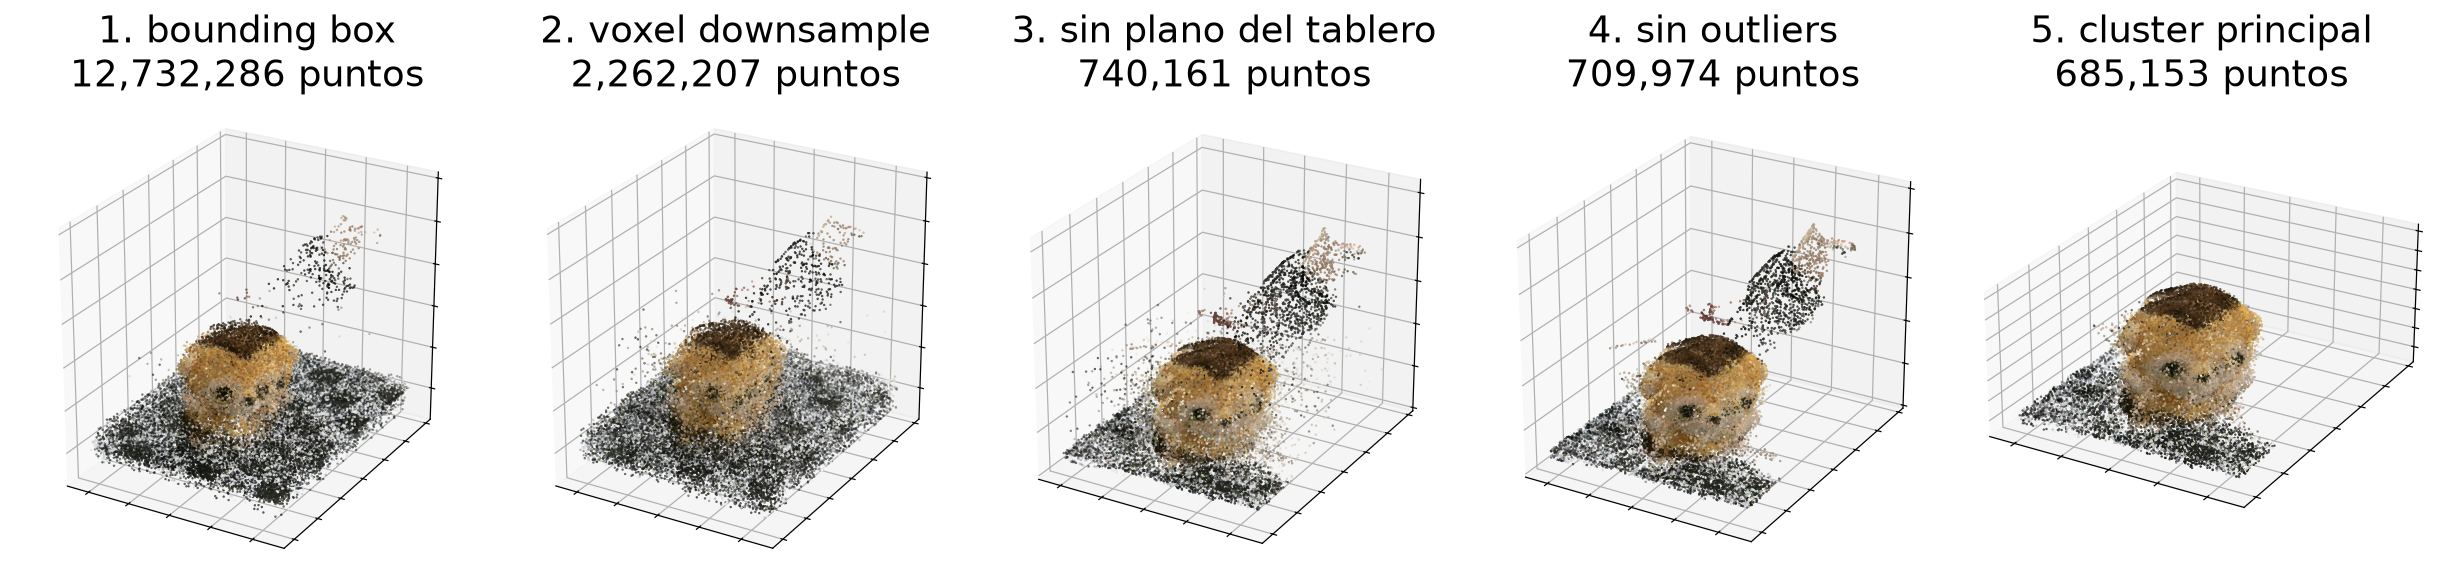

In [14]:
stage_clouds = {}
out = cfg["outliers"]
final, obb, plane, stages = fusion.optimize(
    pcd, cfg["box_min"], cfg["box_max"], cfg["voxel_size"],
    out["nb_neighbors"], out["std_ratio"], plane_margin=cfg.get("plane_margin"),
    clouds=stage_clouds,
)
if cfg.get("largest_cluster_eps"):
    final = fusion.keep_largest_cluster(final, cfg["largest_cluster_eps"])
    stages["largest_cluster"] = len(final.points)
    stage_clouds["largest_cluster"] = final
    print(f"  {'cluster':>13}: {stages['largest_cluster']:>10,} puntos")

rp.save_stages_figure(stage_clouds, os.path.join(fig_dir, "06a_etapas_optimizacion.png"))
show(os.path.join(fig_dir, "06a_etapas_optimizacion.png"), width=1200)

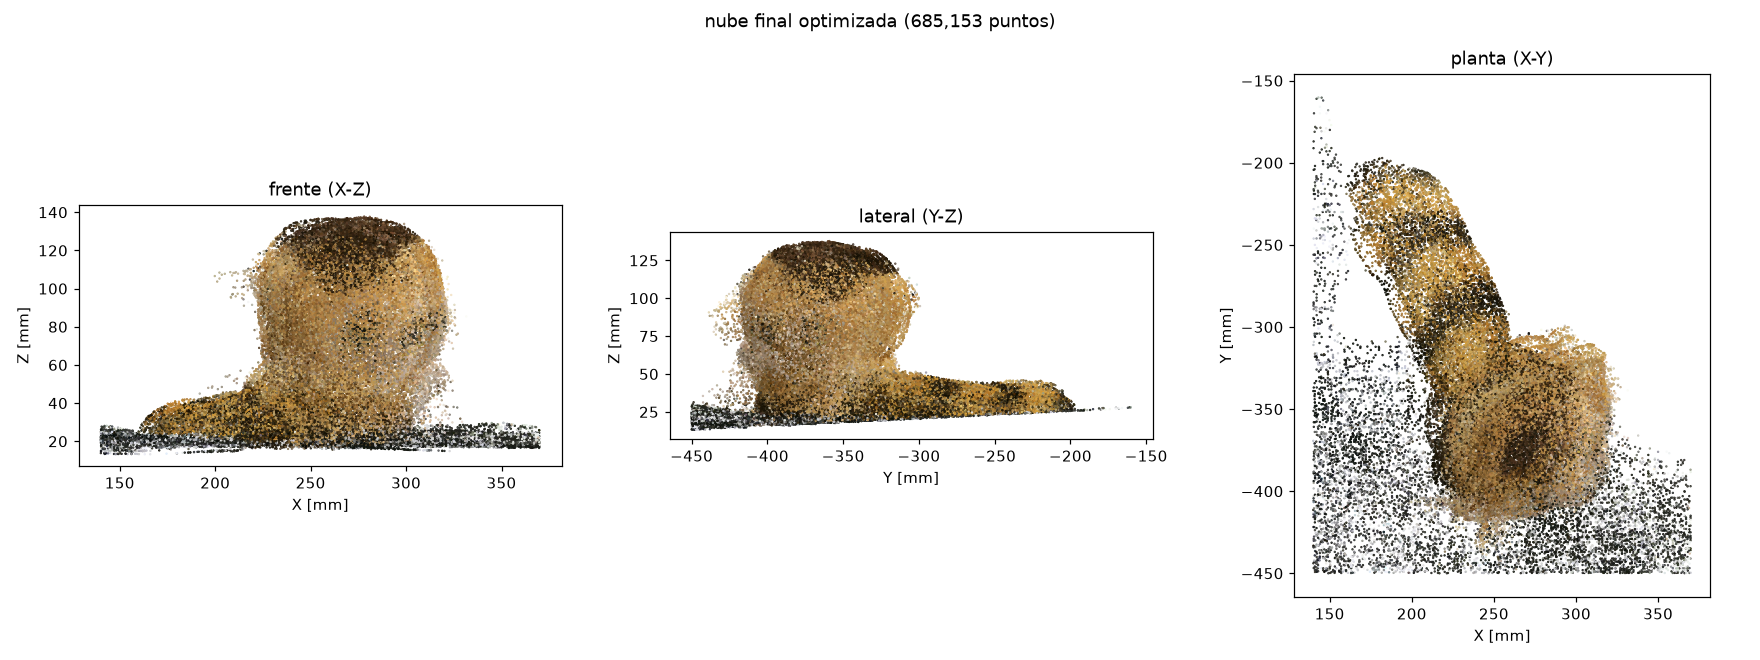

guardado /Users/camidipaola/Desktop/VISION ARTIFICIAL/tp2-grupo/output/grupo/reconstruction.ply (18.5 MB)


In [15]:
rp.save_cloud_views(final, os.path.join(fig_dir, "06_nube_final.png"), "nube final optimizada")
show(os.path.join(fig_dir, "06_nube_final.png"), width=1200)

ply_path = os.path.join(out_dir, "reconstruction.ply")
o3d.io.write_point_cloud(ply_path, final, write_ascii=False)
print(f"guardado {ply_path} ({os.path.getsize(ply_path) / 1e6:.1f} MB)")

Visor interactivo (se puede rotar con el mouse). Funciona en Colab y en Jupyter si está
instalado `plotly`.

In [16]:
SHOW_3D = COLAB   # local: poner True para verlo (agrega varios MB al notebook)
if SHOW_3D:
    o3d.visualization.draw_plotly([final.voxel_down_sample(3.0)])

## 6. Malla con Poisson (opcional)

Normales por vecindad → reconstrucción de Poisson → se descartan los vértices de baja
densidad (superficie que Poisson "inventa" donde no hay datos) → simplificación.

199,999 triángulos -> /Users/camidipaola/Desktop/VISION ARTIFICIAL/tp2-grupo/output/grupo/reconstruction_mesh.ply


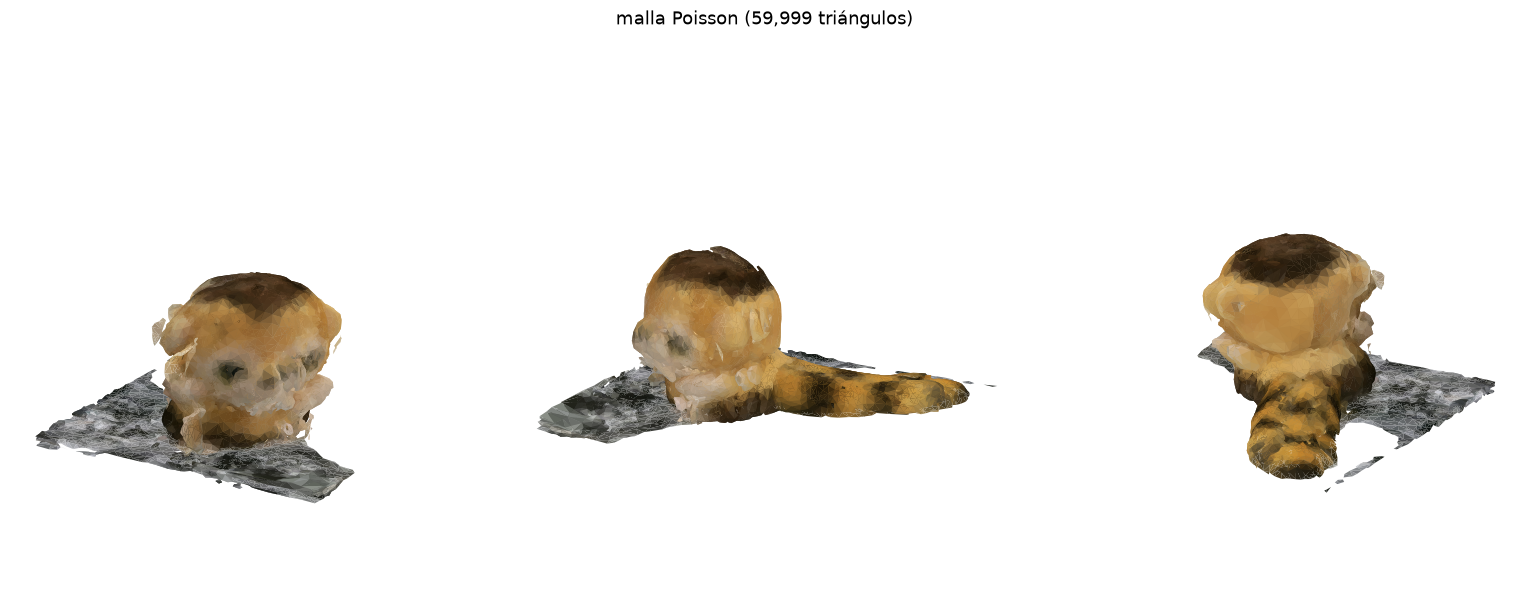

In [17]:
pc = cfg.get("poisson") or {}
mesh = fusion.poisson_mesh(final, depth=pc.get("depth", 8), normal_radius=pc.get("normal_radius", 5.0),
                           density_quantile=pc.get("density_quantile", 0.05),
                           target_triangles=pc.get("target_triangles", 200_000))
mesh_path = os.path.join(out_dir, "reconstruction_mesh.ply")
o3d.io.write_triangle_mesh(mesh_path, mesh)
print(f"{len(mesh.triangles):,} triángulos -> {mesh_path}")

rp.save_mesh_figure(mesh, os.path.join(fig_dir, "07_malla_poisson.png"))
show(os.path.join(fig_dir, "07_malla_poisson.png"), width=1200)

## 7. Medición métrica

La reconstrucción está en **milímetros** sin ambigüedad de escala porque:
- el **baseline** de la calibración estéreo está en mm (el checkerboard tiene tamaño conocido), y
  la profundidad sale de `Z = f·B/d`;
- la pose se estima contra el ChArUco, cuyas medidas también son conocidas.

Alto = distancia al plano del tablero (percentil 99.5, para no depender de un punto espurio).
Ancho y profundidad = extensión en X e Y (percentiles 0.5–99.5).

In [18]:
m = fusion.measure(final, plane)
print(f"alto (sobre el plano de apoyo): {m['height_mm']:.1f} mm  (máximo {m['height_max_mm']:.1f} mm)")
print(f"ancho X: {m['width_x_mm']:.1f} mm | profundidad Y: {m['depth_y_mm']:.1f} mm")

if cfg.get("real_height_mm"):
    rel = abs(m["height_mm"] - cfg["real_height_mm"]) / cfg["real_height_mm"]
    print(f"alto real: {cfg['real_height_mm']} mm -> error relativo {rel:.1%}")

alto (sobre el plano de apoyo): 130.5 mm  (máximo 134.1 mm)
ancho X: 216.9 mm | profundidad Y: 238.9 mm
